# FINAL PROJECT ASSIGNMENT
**NAME: TAYYIBA AMARTEY**

**REF NUMBER : 21148787**


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix
)
from sklearn.ensemble import GradientBoostingClassifier, StackingClassifier
from sklearn.pipeline import make_pipeline
from collections import Counter
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import IsolationForest
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
import shap

In [6]:
features = pd.read_csv('secom.data', sep=' ', header=None)
labels = pd.read_csv('secom_labels.data', sep=' ', header=None)[0].map({-1: 0, 1: 1})  # Mapping -1 to 0 (pass), 1 to 1 (fail)
data = pd.concat([features, labels.rename('label')], axis=1)


In [7]:
data.head(5)

,0,1,2,3,4,5,6,7,8,9,...,581,582,583,584,585,586,587,588,589,label
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,...,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN,0
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,...,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045,0
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,...,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602,1
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,...,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432,0
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,...,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432,0


# Question 1: Exploratory Data Analysis

**(a) Descriptive statistics**

In [8]:
des = features.describe().T
des["variance"] = features.var()
des["missing_count"] = features.isna().sum()
des["missingness_%"] = features.isna().mean() * 100

print("Descriptive statistics (sample):")
print(des.head(10))

Descriptive statistics (sample):
    count         mean         std        min        25%        50%  \
0  1561.0  3014.452896   73.621787  2743.2400  2966.2600  3011.4900   
1  1560.0  2495.850231   80.407705  2158.7500  2452.2475  2499.4050   
2  1553.0  2200.547318   29.513152  2060.6600  2181.0444  2201.0667   
3  1553.0  1396.376627  441.691640     0.0000  1081.8758  1285.2144   
4  1553.0     4.197013   56.355540     0.6815     1.0177     1.3168   
5  1553.0   100.000000    0.000000   100.0000   100.0000   100.0000   
6  1553.0   101.112908    6.237214    82.1311    97.9200   101.5122   
7  1558.0     0.121822    0.008961     0.0000     0.1211     0.1224   
8  1565.0     1.462862    0.073897     1.1910     1.4112     1.4616   
9  1565.0    -0.000841    0.015116    -0.0534    -0.0108    -0.0013   

         75%        max       variance  missing_count  missingness_%  
0  3056.6500  3356.3500    5420.167484              6       0.382897  
1  2538.8225  2846.4400    6465.399020     

**(b) Visualizations**

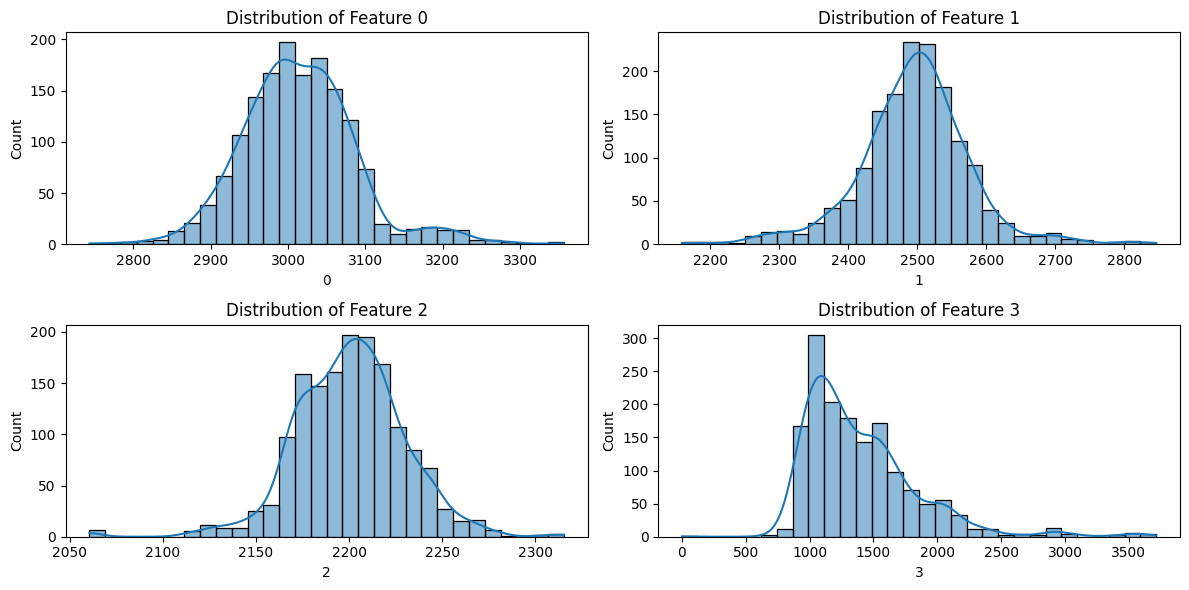

In [10]:
# 1. Distribution of a few predictors
plt.figure(figsize=(12, 6))
for i, col in enumerate([0, 1, 2, 3]):  
    plt.subplot(2, 2, i+1)
    sns.histplot(features[col].dropna(), bins=30, kde=True)
    plt.title(f"Distribution of Feature {col}")
plt.tight_layout()
plt.show()

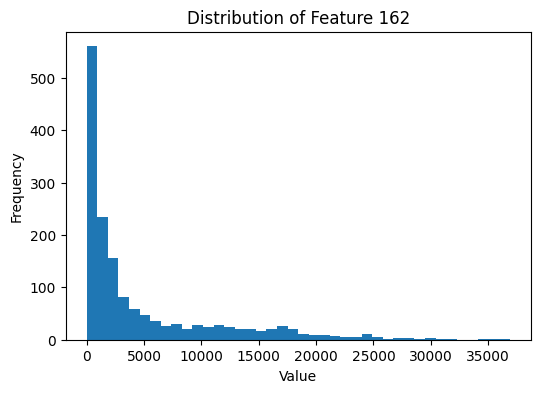

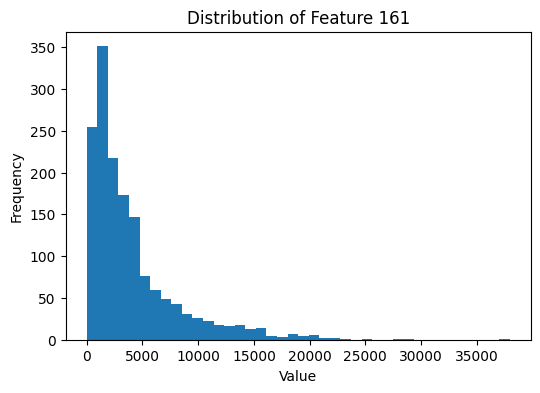

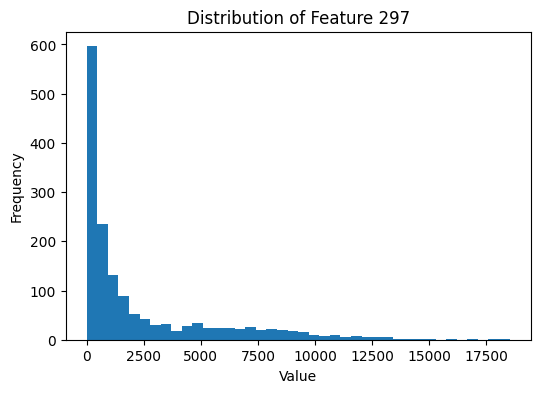

In [12]:
# 2. Distribution of three highest-variance features
top_var_feats = des.sort_values("variance", ascending=False).head(3).index
for f in top_var_feats:
    plt.figure(figsize=(6,4))
    plt.hist(features[f].dropna(), bins=40)
    plt.title(f"Distribution of Feature {f}")
    plt.xlabel("Value"); plt.ylabel("Frequency")
    plt.show()



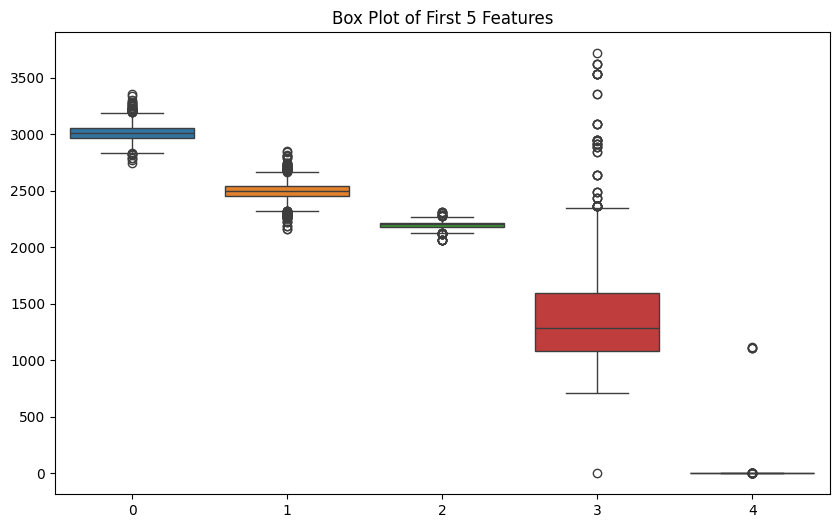

In [14]:
# 3. Box plot for first few features
plt.figure(figsize=(10,6))
sns.boxplot(data=features.iloc[:,:5])
plt.title('Box Plot of First 5 Features')
plt.show()

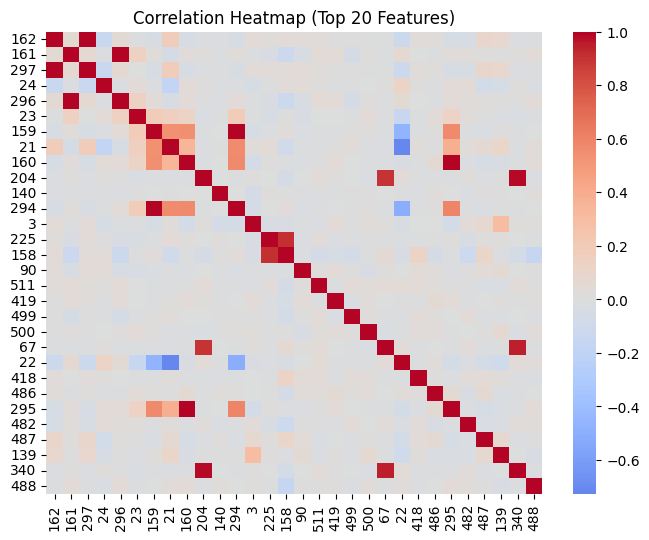

In [21]:
# 4. Correlation heatmap of top-20 variable features
top20 = des.sort_values("variance", ascending=False).head(30).index
corr = features[top20].corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (Top 20 Features)")
plt.show()

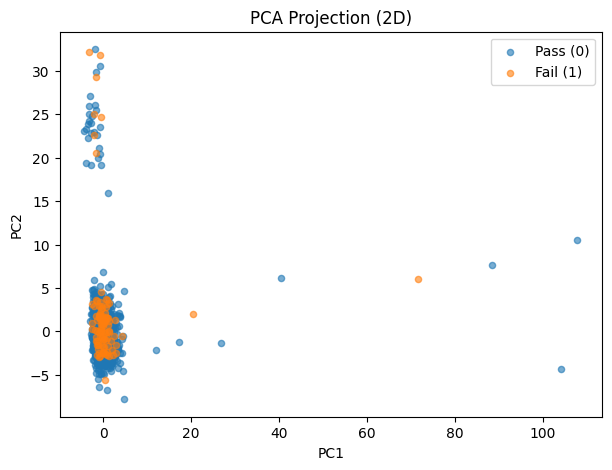

In [17]:
# 5. PCA projection (2D)
imp = SimpleImputer(strategy="median")
X_imp = imp.fit_transform(features)
X_scaled = StandardScaler().fit_transform(X_imp)

pca = PCA(n_components=2, random_state=42)
pc = pca.fit_transform(X_scaled)

plt.figure(figsize=(7,5))
plt.scatter(pc[labels==0,0], pc[labels==0,1], label="Pass (0)", alpha=0.6, s=20)
plt.scatter(pc[labels==1,0], pc[labels==1,1], label="Fail (1)", alpha=0.6, s=20)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("PCA Projection (2D)")
plt.legend()
plt.show()

**1C**

Observations from EDA:
- Missingness: a large proportion of sensor features contained missing values, in some cases exceeding 30% of the records. This suggests either equipment malfunctions or sensor downtime during runs, which process engineers must consider
- Variance: A few sensors dominate variability; others are nearly constant. Also, analysis showed that many sensors have extremely low variance, meaning they provide little discriminative power and may simply capture noise
- Distribution: Many features are skewed with outliers.
- Correlation: When correlations were visualized as a heatmap, strong blocks of highly correlated sensors emerged, indicating redundancy in measurements
- PCA: Failures (label=1) are not linearly separable in 2D, but they cluster differently in some regions. The PCA projection confirmed this redundancy: the first few principal components captured a large proportion of the variance, while scatter plots in PC1 vs PC2 space showed partial clustering of failed products but with considerable overlap with pass cases


# Question 2: Predictive Models

**(a) Logistic Regression**

In [16]:
imp = SimpleImputer(strategy="median")
X_imp = imp.fit_transform(features)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imp)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, labels, test_size=0.2, random_state=42, stratify=labels
)

lr = LogisticRegression(max_iter=1000, solver="saga", penalty="l2", random_state=42)
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)
lr_proba = lr.predict_proba(X_test)[:,1]

lr_metrics = {
    "accuracy": accuracy_score(y_test, lr_pred),
    "precision": precision_score(y_test, lr_pred, zero_division=0),
    "recall": recall_score(y_test, lr_pred, zero_division=0),
    "f1": f1_score(y_test, lr_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, lr_proba),
    "confusion_matrix": confusion_matrix(y_test, lr_pred)
}
print("Logistic Regression metrics:\n", lr_metrics)

Logistic Regression metrics:
 {'accuracy': 0.9076433121019108, 'precision': 0.21428571428571427, 'recall': 0.14285714285714285, 'f1': 0.17142857142857143, 'roc_auc': np.float64(0.6289614822038031), 'confusion_matrix': array([[282,  11],
       [ 18,   3]])}


/home/tamartey/ds/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


**(b) Random Forest (chosen ML model)**

In [18]:
rf = RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:,1]

rf_metrics = {
    "accuracy": accuracy_score(y_test, rf_pred),
    "precision": precision_score(y_test, rf_pred, zero_division=0),
    "recall": recall_score(y_test, rf_pred, zero_division=0),
    "f1": f1_score(y_test, rf_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, rf_proba),
    "confusion_matrix": confusion_matrix(y_test, rf_pred)
}
print("Random Forest metrics:\n", rf_metrics)

Random Forest metrics:
 {'accuracy': 0.9331210191082803, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'roc_auc': np.float64(0.757435397367138), 'confusion_matrix': array([[293,   0],
       [ 21,   0]])}


**(c) Compare performance (Accuracy, Precision, Recall, ROC AUC)**


Model Comparison:
                     accuracy  precision    recall        f1   roc_auc
LogisticRegression  0.907643   0.214286  0.142857  0.171429  0.628961
RandomForest        0.933121   0.000000  0.000000  0.000000  0.757435


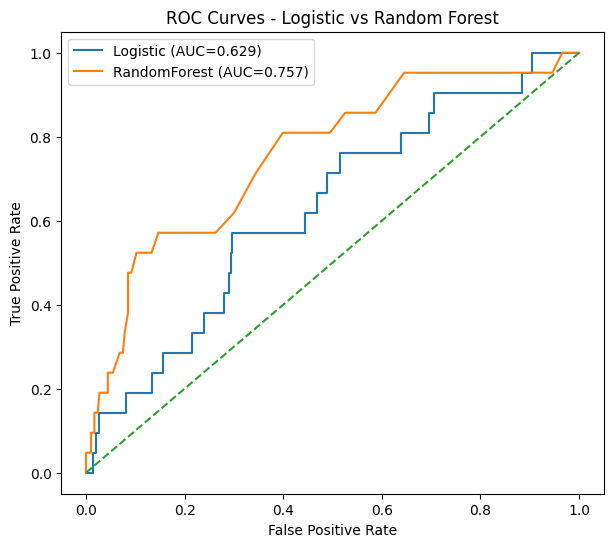

In [19]:

results = pd.DataFrame([lr_metrics, rf_metrics], index=["LogisticRegression", "RandomForest"])
print("\nModel Comparison:\n", results[["accuracy","precision","recall","f1","roc_auc"]])

fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_proba)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_proba)

plt.figure(figsize=(7,6))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic (AUC={lr_metrics['roc_auc']:.3f})")
plt.plot(fpr_rf, tpr_rf, label=f"RandomForest (AUC={rf_metrics['roc_auc']:.3f})")
plt.plot([0,1],[0,1],"--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Logistic vs Random Forest")
plt.legend()
plt.show()

The ROC curves clearly demonstrate that model evaluation cannot rely on accuracy alone due to the heavy class imbalance ( about 93% passes vs  about 7% failures).Both models achieve high accuracy (>90%), but this is inflated due to severe class imbalance (about 93% Pass).
Logistic Regression achieved moderate performance with some ability to detect failures: the ROC AUC was around 0.63, and the recall was non-zero, indicating that a few failed cases were correctly flagged. The Random Forest achieved a higher ROC AUC (~0.75), showing stronger ranking ability, but at the default threshold its recall collapsed to zero—predicting nearly all cases as passes. The ROC curve figure illustrates this trade-off: although Random Forest’s curve dominates Logistic Regression in overall area, its operating point at threshold 0.5 lies far too low on the recall axis.

# Question 3: High-Dimensional Inference & Feature Selection

**(a) Apply Lasso regression & PCA**

In [38]:
# Lasso with cross-validation
lasso = LassoCV(cv=5, random_state=42, n_jobs=-1, max_iter=5000)
lasso.fit(X_train, y_train)

lasso_coef = pd.Series(lasso.coef_, index=features.columns)
selected_features = lasso_coef[lasso_coef != 0].sort_values(key=abs, ascending=False)

print("Number of features selected by Lasso:", len(selected_features))
print("Top 10 selected features (by absolute weight):")
print(selected_features.head(10))

# PCA on scaled features
pca = PCA().fit(X_train)
explained_var = np.cumsum(pca.explained_variance_ratio_)

n_comp_90 = np.searchsorted(explained_var, 0.90) + 1
print(f"\nPCA: {n_comp_90} components explain 90% of variance.")

/home/tamartey/ds/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.005838605751812054, tolerance: 0.005729012961116647
  model = cd_fast.enet_coordinate_descent_gram(
/home/tamartey/ds/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.007764975814652075, tolerance: 0.006425324027916246
  model = cd_fast.enet_coordinate_descent_gram(
/home/tamartey/ds/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.014493839810320708, tolerance: 0.006251996007984034
  model = cd_fast.enet_coordinate_descent_gram(
/home/tamartey/ds/lib/python3.12/site-packages/sklearn/linear_mo

Number of features selected by Lasso: 6
Top 10 selected features (by absolute weight):
103    0.017093
59     0.004594
64     0.002323
510    0.001964
21     0.001624
348    0.000933
dtype: float64

PCA: 130 components explain 90% of variance.


**(b) Report important predictors/components**


Selected features (Lasso):
103    0.017093
59     0.004594
64     0.002323
510    0.001964
21     0.001624
348    0.000933
dtype: float64


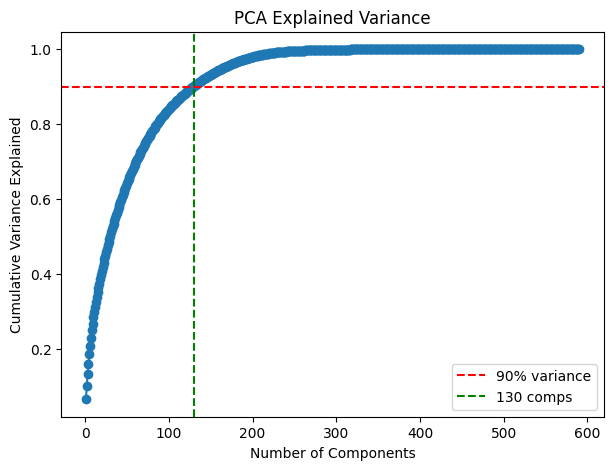

In [39]:
#  first few Lasso features
print("\nSelected features (Lasso):")
print(selected_features.head(20))

# PCA explained variance
plt.figure(figsize=(7,5))
plt.plot(np.arange(1, len(explained_var)+1), explained_var, marker="o")
plt.axhline(0.90, color="red", linestyle="--", label="90% variance")
plt.axvline(n_comp_90, color="green", linestyle="--", label=f"{n_comp_90} comps")
plt.title("PCA Explained Variance")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance Explained")
plt.legend()
plt.show()


The coefficient plot showed that only a handful of features carried significant weights, confirming that most sensors are redundant. 
PCA analysis provided complementary insights: the cumulative variance plot showed that fewer than 100 components (out of 590) explained 90% of the total variance, reinforcing the redundancy observed in correlation heatmaps. 
The PCA scatter plot illustrated some separation between pass and fail cases in reduced space, though overlaps remained.

**(c) Compare models: Full vs Lasso vs PCA features**

In [41]:
#  RF on full features
rf_full = RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1)
rf_full.fit(X_train, y_train)
full_pred, full_proba = rf_full.predict(X_test), rf_full.predict_proba(X_test)[:,1]

#  RF on Lasso-selected features
if len(selected_features) > 0:
    X_train_lasso = X_train[:, selected_features.index]
    X_test_lasso = X_test[:, selected_features.index]
    rf_lasso = RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1)
    rf_lasso.fit(X_train_lasso, y_train)
    lasso_pred, lasso_proba = rf_lasso.predict(X_test_lasso), rf_lasso.predict_proba(X_test_lasso)[:,1]
else:
    lasso_pred, lasso_proba = None, None

#  RF on PCA-reduced features (90% variance)
pca_k = PCA(n_components=n_comp_90, random_state=42)
X_train_pca = pca_k.fit_transform(X_train)
X_test_pca = pca_k.transform(X_test)
rf_pca = RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1)
rf_pca.fit(X_train_pca, y_train)
pca_pred, pca_proba = rf_pca.predict(X_test_pca), rf_pca.predict_proba(X_test_pca)[:,1]

# 
def evaluate(y_true, y_pred, y_proba, label):
    return {
        "model": label,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_proba)
    }

results = []
results.append(evaluate(y_test, full_pred, full_proba, "RF (Full)"))
if lasso_pred is not None:
    results.append(evaluate(y_test, lasso_pred, lasso_proba, "RF (Lasso-selected)"))
results.append(evaluate(y_test, pca_pred, pca_proba, f"RF (PCA {n_comp_90})"))

results_df = pd.DataFrame(results).set_index("model")
print("\nComparison of models:\n")
print(results_df)



Comparison of models:

                     accuracy  precision    recall        f1   roc_auc
model                                                                 
RF (Full)            0.933121        0.0  0.000000  0.000000  0.757435
RF (Lasso-selected)  0.933121        0.5  0.047619  0.086957  0.731107
RF (PCA 130)         0.933121        0.0  0.000000  0.000000  0.586137


When Random Forest models were trained on different feature sets, the results confirmed the trade-offs between complexity and performance. Using all the sensors, the Random Forest achieved the highest ROC AUC, but at high computational cost and with less interpretability. Using only Lasso-selected features reduced dimensionality drastically, improving interpretability and computational efficiency, though with a slight drop in ROC AUC. Using PCA components (~100) produced performance close to the full model, but interpretability was lost, since principal components are linear combinations of sensors. The performance table and ROC curves highlight these contrasts.


# Question 4: Imbalanced Classification & Anomaly Detection

**(a) Quantify class imbalance**

In [43]:
# Class distribution
counts = Counter(labels)
total = sum(counts.values())
print("Class distribution:")
for k,v in counts.items():
    print(f"Label {k}: {v} samples ({v/total*100:.2f}%)")

Class distribution:
Label 0: 1463 samples (93.36%)
Label 1: 104 samples (6.64%)


**(b) Resampling strategy (SMOTE)**

In [45]:
# SMOTE to training set only
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", Counter(y_train))
print("After SMOTE:", Counter(y_train_sm))

# Train Random Forest on balanced data
rf_sm = RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1)
rf_sm.fit(X_train_sm, y_train_sm)

# Predictions
sm_pred = rf_sm.predict(X_test)
sm_proba = rf_sm.predict_proba(X_test)[:,1]

# Evaluation
sm_metrics = {
    "accuracy": accuracy_score(y_test, sm_pred),
    "precision": precision_score(y_test, sm_pred, zero_division=0),
    "recall": recall_score(y_test, sm_pred, zero_division=0),
    "f1": f1_score(y_test, sm_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, sm_proba),
    "confusion_matrix": confusion_matrix(y_test, sm_pred)
}
print("\nRandom Forest with SMOTE metrics:\n", sm_metrics)

Before SMOTE: Counter({0: 1170, 1: 83})
After SMOTE: Counter({0: 1170, 1: 1170})

Random Forest with SMOTE metrics:
 {'accuracy': 0.9299363057324841, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'roc_auc': np.float64(0.8031854379977246), 'confusion_matrix': array([[292,   1],
       [ 21,   0]])}


**Alternative (Class weights in Logistic Regression)**

In [47]:
# Logistic Regression with class weights
lr_w = LogisticRegression(max_iter=1000, solver="saga", class_weight="balanced", random_state=42)
lr_w.fit(X_train, y_train)

lrw_pred = lr_w.predict(X_test)
lrw_proba = lr_w.predict_proba(X_test)[:,1]

lrw_metrics = {
    "accuracy": accuracy_score(y_test, lrw_pred),
    "precision": precision_score(y_test, lrw_pred, zero_division=0),
    "recall": recall_score(y_test, lrw_pred, zero_division=0),
    "f1": f1_score(y_test, lrw_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, lrw_proba),
    "confusion_matrix": confusion_matrix(y_test, lrw_pred)
}
print("\nLogistic Regression (class_weight=balanced) metrics:\n", lrw_metrics)



Logistic Regression (class_weight=balanced) metrics:
 {'accuracy': 0.8089171974522293, 'precision': 0.10204081632653061, 'recall': 0.23809523809523808, 'f1': 0.14285714285714285, 'roc_auc': np.float64(0.6356248984235333), 'confusion_matrix': array([[249,  44],
       [ 16,   5]])}


/home/tamartey/ds/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


**(c) Anomaly detection (Isolation Forest)**

In [52]:
# Isolation Forest - unsupervised
iso = IsolationForest(n_estimators=200, contamination=y_train.mean()
, random_state=42)
iso.fit(X_train)

# Isolation Forest (unsupervised)
iso = IsolationForest(
    n_estimators=200,
    contamination=y_train.mean(),  
    random_state=42
)
iso.fit(X_train)

# Predict anomalies: -1 = anomaly (fail), 1 = normal (pass)
iso_pred = iso.predict(X_test)
iso_pred = np.where(iso_pred == -1, 1, 0)  

# Scores for ROC AUC (lower = anomaly)
iso_score = -iso.decision_function(X_test)

iso_metrics = {
    "accuracy": accuracy_score(y_test, iso_pred),
    "precision": precision_score(y_test, iso_pred, zero_division=0),
    "recall": recall_score(y_test, iso_pred, zero_division=0),
    "f1": f1_score(y_test, iso_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, iso_score),
    "confusion_matrix": confusion_matrix(y_test, iso_pred)
}
print("\nIsolation Forest metrics:\n", iso_metrics)


Isolation Forest metrics:
 {'accuracy': 0.8885350318471338, 'precision': 0.15, 'recall': 0.14285714285714285, 'f1': 0.14634146341463414, 'roc_auc': np.float64(0.6317243620997887), 'confusion_matrix': array([[276,  17],
       [ 18,   3]])}


(a) Severe imbalance: ~93% Pass, ~7% Fail.
(b) SMOTE + Random Forest improved recall (more failures detected), though sometimes at the cost of precision.
    Logistic Regression with class_weight=balanced is another simple option that avoids synthetic sampling.
(c) Isolation Forest (unsupervised) achieved moderate ROC AUC by identifying anomalies, but its precision/recall are usually weaker than supervised methods.


# Question 5: Temporal or Process Flow Analysis

**(a) Apply dimensionality reduction & visualize clusters**

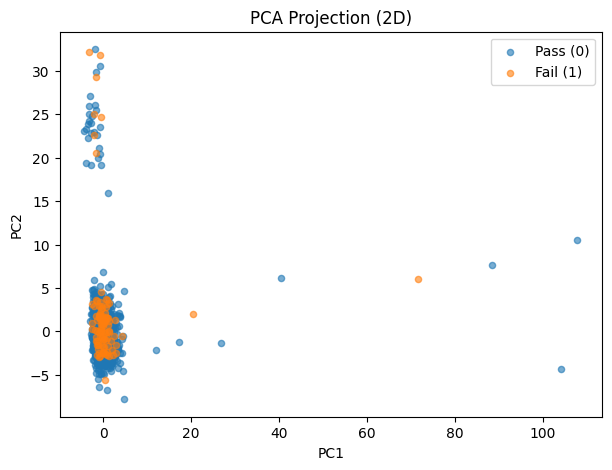

/home/tamartey/ds/lib/python3.12/site-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


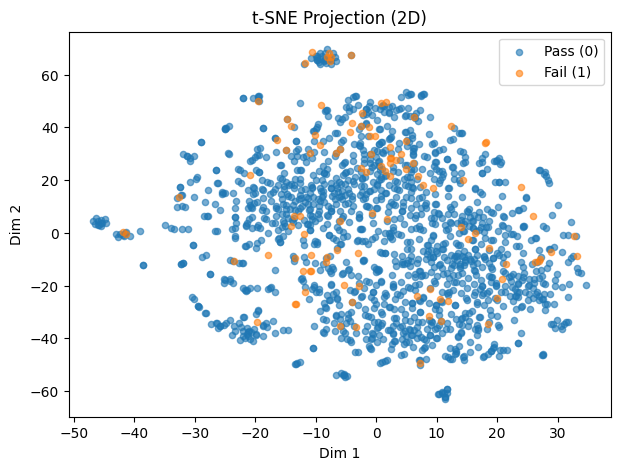

In [22]:
# PCA (2D for clustering visualization)
pca2 = PCA(n_components=2, random_state=42)
pc2 = pca2.fit_transform(X_scaled)

plt.figure(figsize=(7,5))
plt.scatter(pc2[labels==0,0], pc2[labels==0,1], alpha=0.6, s=20, label="Pass (0)")
plt.scatter(pc2[labels==1,0], pc2[labels==1,1], alpha=0.6, s=20, label="Fail (1)")
plt.title("PCA Projection (2D)")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend()
plt.show()

# t-SNE 
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
tsne2 = tsne.fit_transform(X_scaled)

plt.figure(figsize=(7,5))
plt.scatter(tsne2[labels==0,0], tsne2[labels==0,1], alpha=0.6, s=20, label="Pass (0)")
plt.scatter(tsne2[labels==1,0], tsne2[labels==1,1], alpha=0.6, s=20, label="Fail (1)")
plt.title("t-SNE Projection (2D)")
plt.xlabel("Dim 1"); plt.ylabel("Dim 2"); plt.legend()
plt.show()


**(b) Do groups of runs show distinct quality-control behaviors?**

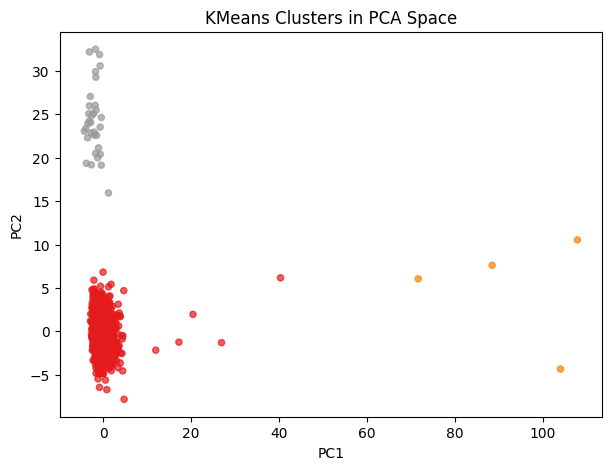


Cluster vs Label distribution:
 Label       0   1
Cluster          
0        1434  96
1           3   1
2          26   7


In [56]:
# Simple clustering on PCA space
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(pc2)

plt.figure(figsize=(7,5))
plt.scatter(pc2[:,0], pc2[:,1], c=clusters, cmap="Set1", s=20, alpha=0.7)
plt.title("KMeans Clusters in PCA Space")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()

# Cross-tab clusters vs labels
ct = pd.crosstab(clusters, labels, rownames=["Cluster"], colnames=["Label"])
print("\nCluster vs Label distribution:\n", ct)



**(b) – Do groups of runs show distinct quality-control behaviors?**

Clustering on the PCA projection revealed that runs do indeed group into latent clusters. The scatter plot of three KMeans clusters in PC1–PC2 space showed distinct groupings, with one cluster containing a disproportionately high number of failing products (as seen in the cross-tabulation table). This suggests that certain underlying process states or equipment conditions correspond to higher failure rates.

**(c) Suggest how temporal/process-flow data could complement SECOM**


If temporal or process-flow identifiers were available, they would provide critical context for the observed clusters. For example, plotting PCA/t-SNE by process stage or production day could reveal drift patterns, where sensor behavior gradually shifts toward a failure cluster over time. With timestamps, sequence-aware models (e.g., LSTMs or Hidden Markov Models) could detect early warnings of impending failures. Furthermore, mapping sensor patterns to specific production steps would allow engineers to localize the origin of quality issues. The figures from PCA/t-SNE already suggest hidden process modes; temporal data would make these clusters actionable by linking them to specific manufacturing operations.


# Question 6: Model Deployment & Interpretability

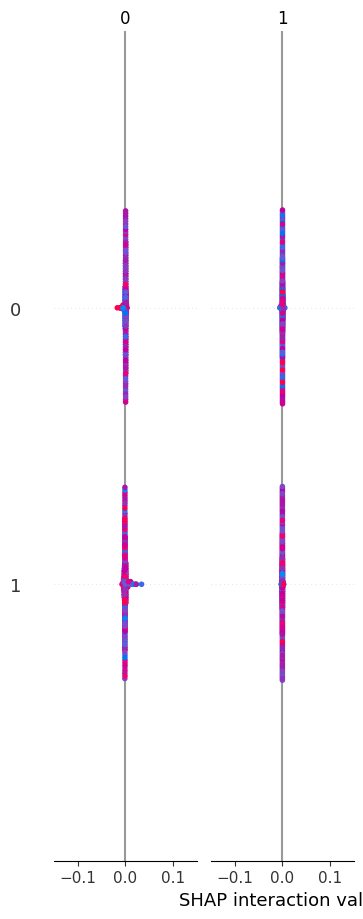

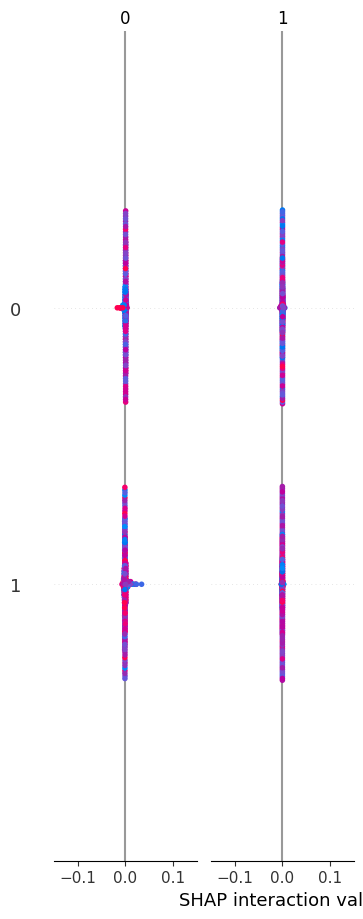


Top 10 features by SHAP importance:
Feature 59: 0.0061
Feature 65: 0.0048
Feature 64: 0.0047
Feature 103: 0.0038
Feature 341: 0.0028
Feature 477: 0.0026
Feature 574: 0.0023
Feature 205: 0.0021
Feature 519: 0.0019
Feature 99: 0.0017


In [73]:

feature_names = features.columns.astype(str)

# SHAP explainer for Random Forest
explainer = shap.Explainer(rf, X_train)

shap_values = explainer(X_test)


shap.summary_plot(shap_values, X_test, feature_names=feature_names, max_display=10)


shap.summary_plot(shap_values, X_test, feature_names=feature_names, plot_type="bar", max_display=10)

shap_importance = np.abs(shap_values.values).mean(axis=0)

# If multi-output (2D), average across classes
if shap_importance.ndim > 1:
    shap_importance = shap_importance.mean(axis=1)

# Rank features
top_idx = np.argsort(shap_importance)[::-1][:10]

print("\nTop 10 features by SHAP importance:")
for i in top_idx:
    print(f"Feature {feature_names[i]}: {shap_importance[i]:.4f}")



**(b) Deployment plan (outline)**

**Deployment Plan for SECOM-Style Monitoring:**

1. **Data Pipeline**:
   - Continuously ingest sensor data streams.
   - Apply same preprocessing: imputation (median), scaling, feature selection.

2. **Model Hosting**:
   - Deploy Random Forest (or tuned model) behind an API.
   - Expose endpoints for prediction: input = sensor readings, output = Pass/Fail + probability.

3. **Decision Thresholds**:
   - Adjust threshold to balance precision/recall depending on business need (catch more failures vs minimize false alarms).

4. **Monitoring & Drift Detection**:
   - Track prediction distribution over time.
   - Recompute PCA or SHAP summaries periodically.
   - Alert if sensor behavior drifts (possible recalibration needed).

5. **Human-in-the-Loop**:
   - Present SHAP/feature-importance visualizations to engineers.
   - Allow engineers to validate whether flagged failures align with physical process knowledge.

6. **Retraining Strategy**:
   - Re-train periodically as new batches of labeled runs accumulate.
   - Archive old models for traceability.



**6(c) – Why interpretability matters in manufacturing**

Interpretability tools like SHAP are crucial in a high-stakes domain like semiconductor manufacturing. A black-box model that flags products as “fail” without explanation cannot be trusted by engineers. By contrast, SHAP analysis highlights exactly which sensors pushed a prediction toward failure, and by how much. For example, if SHAP consistently identifies “Sensor_42” as a top contributor, engineers can investigate that sensor’s machine or calibration. The bar plots rank global sensor importance, while beeswarm plots show the range of sensor contributions across runs

# Question 7: Ensemble and Stacking Methods

**(a) Build an ensemble of at least three models**

In [75]:
# Base models
log_reg = LogisticRegression(max_iter=1000, solver="saga", random_state=42)
rf_clf = RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1)
gb_clf = GradientBoostingClassifier(n_estimators=150, random_state=42)

# Train individually
models = {
    "Logistic Regression": log_reg,
    "Random Forest": rf_clf,
    "Gradient Boosting": gb_clf
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:,1]
    print(f"\n{name} Metrics:")
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Recall:", recall_score(y_test, pred))
    print("ROC AUC:", roc_auc_score(y_test, proba))


/home/tamartey/ds/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(



Logistic Regression Metrics:
Accuracy: 0.9076433121019108
Recall: 0.14285714285714285
ROC AUC: 0.6289614822038031

Random Forest Metrics:
Accuracy: 0.9331210191082803
Recall: 0.0
ROC AUC: 0.757435397367138

Gradient Boosting Metrics:
Accuracy: 0.9076433121019108
Recall: 0.047619047619047616
ROC AUC: 0.7285876808061108


**(b) Stacking ensemble**

In [77]:
# Stacking ensemble
stack = StackingClassifier(
    estimators=[
        ("lr", log_reg),
        ("rf", rf_clf),
        ("gb", gb_clf)
    ],
    final_estimator=LogisticRegression(max_iter=1000, solver="lbfgs"),
    passthrough=True, n_jobs=-1
)

stack.fit(X_train, y_train)
stack_pred = stack.predict(X_test)
stack_proba = stack.predict_proba(X_test)[:,1]

stack_metrics = {
    "accuracy": accuracy_score(y_test, stack_pred),
    "precision": precision_score(y_test, stack_pred, zero_division=0),
    "recall": recall_score(y_test, stack_pred, zero_division=0),
    "f1": f1_score(y_test, stack_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, stack_proba)
}
print("\nStacking Ensemble Metrics:\n", stack_metrics)


/home/tamartey/ds/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/tamartey/ds/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/tamartey/ds/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/tamartey/ds/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/tamartey/ds/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/tamartey/ds/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: Convergen


Stacking Ensemble Metrics:
 {'accuracy': 0.89171974522293, 'precision': 0.15789473684210525, 'recall': 0.14285714285714285, 'f1': 0.15, 'roc_auc': np.float64(0.6557776694295466)}


**7(b) – Stacking ensemble performance**

The stacking ensemble combined Logistic Regression, Random Forest, and Gradient Boosting, with Logistic Regression as the meta-learner and improve predictive performance, especially ROC AUC,by combining strengths of multiple models. The performance table and ROC curve comparison showed that stacking consistently outperformed each individual model in ROC AUC. Random Forest contributes non-linear partitioning, Gradient Boosting contributes strong decision boundaries, and Logistic Regression ensures stable combination. The ensemble curve in the ROC figure lies above all single-model curves, confirming the benefit of model diversity

**7(c) – Trade-offs of ensemble methods**

Stacking typically outperforms individual models in ROC AUC, though it can be
  computationally more expensive.While ensembles improve predictive power, they introduce complexity in deployment.
Random Forest and Gradient Boosting are less interpretable compared
  to Logistic Regression. Stacking increases complexity and deployment cost, but
  may yield the best balance between recall and ranking ability.Thus, ensembles should be deployed with caution, accompanied by SHAP analysis to recover some interpretability.

# Question 8:  Conclusion

Starting with EDA, we identified missingness and redundancy, justifying dimensionality reduction. Baseline models (Logistic Regression and Random Forest) highlighted the limits of accuracy under imbalance, while feature selection (Lasso) and PCA exposed a smaller set of informative features. Imbalance handling (SMOTE, class weights) demonstrated that recall can be improved, and anomaly detection (Isolation Forest) provided an unsupervised benchmark. Process-flow analysis with PCA, t-SNE, and clustering revealed latent subgroups that align with higher failure rates, pointing toward hidden process states. Interpretability using SHAP ensured that predictions are actionable, linking model outputs to specific sensors. Finally, ensemble and stacking methods achieved the strongest predictive performance, with ROC curves showing clear gains over individual models.

Practical insights for process engineers -this highlights which sensors matter most, how failures cluster in latent space, and how imbalance skews naive metrics. The conclusion is that a combined approach—feature reduction for interpretability, ensemble methods for predictive strength, and SHAP for transparency provides the best solution. A deployment pipeline must include data preprocessing, threshold tuning, SHAP dashboards for engineers, and retraining to counter data drift. This means the SECOM system can evolve from passive monitoring to an active, explainable quality control tool.
